# Privacy-Preserving Federated Learning for Heart-Disease Prediction
### Objective 5 — comparative study, single-notebook version

**The big picture.** Several hospitals want one shared heart-disease model, but patient records can't leave each hospital.
In *federated learning* every hospital trains on its own data and sends only model updates to a central server, which averages them into a global model.
This notebook simulates that setup and answers one question: **which techniques give the best balance of accuracy, privacy, security and communication cost?**

It runs five experiments, each repeated over several random seeds and checked with paired significance tests:

| # | Experiment | What it compares |
|---|---|---|
| 1 | Algorithms | FedAvg, FedProx, SCAFFOLD, FedNova, FedAdam, FedYogi, FedAdagrad on non-IID hospitals |
| 2 | Privacy | DP-SGD (ε = 1, 5, 10), Local DP, Secure Aggregation, Homomorphic Encryption, DP + SecAgg |
| 3 | Security | Krum, Multi-Krum, Trimmed Mean, Median vs. label-flip / sign-flip / Gaussian attackers, plus adversarial training |
| 4 | Communication | FedPAQ, 2/4/8-bit quantisation, top-k sparsification with error feedback |
| 5 | Framework | The 8 recommended configurations from Table 7 of the report, incl. utility loss and poisoning robustness |

**How to use it:** run the cells top to bottom (*Kernel → Restart & Run All*). Everything the old `.py` files did is inside this one notebook, so nothing else needs to sit next to it.
Change the knobs in the **Settings** cell. Set `QUICK_TEST = True` for a ~1 minute smoke test.

## 1. Setup

In [1]:
import sys, subprocess, importlib

# python-paillier is only needed for the homomorphic-encryption experiment.
try:
    import phe
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "phe"], check=False)
    importlib.invalidate_caches()
    try:
        import phe
    except ImportError:
        phe = None
HAVE_PHE = phe is not None
print("python-paillier available:", HAVE_PHE)

import os, math, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
pd.set_option("display.width", 200, "display.max_columns", 30)

python-paillier available: True


## 2. Settings
These replace the command-line flags of `run_all.py` (`--seeds`, `--rounds`, `--skip-he`, `--only`, `--synthetic`, ...).

In [2]:
QUICK_TEST = False        # True -> 2 seeds, 10 rounds: finishes in about a minute, just to check that everything runs
SEEDS      = 2 if QUICK_TEST else 10     # the report's statistical protocol needs >= 6, preferably 10
ROUNDS     = 10 if QUICK_TEST else 40
SKIP_HE    = False        # Paillier is the slow one (a few minutes at 10 seeds); True skips it
SYNTHETIC  = False        # True forces the built-in synthetic hospitals instead of the UCI data
DATA_DIR   = "data"       # where the four processed.*.data UCI files live / get downloaded to
OUT_DIR    = "results"    # CSVs and PNGs are written here
RUN = ["algorithms", "privacy", "security", "communication", "framework"]   # drop names to run fewer experiments

os.makedirs(OUT_DIR, exist_ok=True)
SEED_LIST = list(range(SEEDS))

## 3. The building blocks
Each cell below is one of the original modules (`config`, `data`, `model`, ...). They are unchanged except where marked **[notebook change]**.

**config** — one dataclass describes a complete experiment.

In [3]:
# ===== config.py =====
"""config.py -- one dataclass that describes a complete federated experiment."""
from dataclasses import dataclass
from typing import Optional, Tuple


@dataclass
class FLConfig:
    name: str = "FedAvg"
    # ---- federated optimisation -------------------------------------------
    algo: str = "fedavg"      # fedavg|fedprox|scaffold|fednova|fedadam|fedyogi|
    #                           fedadagrad|fedpaq
    rounds: int = 40
    local_epochs: int = 2
    het_epochs: Optional[Tuple[int, int]] = None   # random epochs per client/round
    batch_size: int = 32
    lr: float = 0.1                # client learning rate
    l2: float = 1e-3               # L2 regularisation of the logistic model
    mu: float = 0.1                # FedProx proximal coefficient
    server_lr: float = 1.0         # server step size (adaptive methods: ~0.05-0.1)
    beta1: float = 0.9
    beta2: float = 0.99
    tau: float = 1e-3              # adaptivity constant of FedAdam/Yogi/Adagrad
    participation: float = 1.0     # fraction of clients sampled per round
    # ---- privacy -----------------------------------------------------------
    dp: Optional[str] = None       # None | "dpsgd" (example-level) | "ldp"
    clip: float = 1.0              # clipping norm C
    noise_multiplier: Optional[float] = None
    target_eps: Optional[float] = None   # sigma is calibrated to hit this epsilon
    delta: float = 1e-6
    secagg: bool = False           # pairwise-masking secure aggregation
    he: bool = False               # Paillier homomorphic-encryption aggregation
    he_key_bits: int = 1024        # use >= 2048 in a real deployment
    # ---- security ----------------------------------------------------------
    aggregator: str = "mean"       # mean|krum|multikrum|trimmed|median
    n_byzantine: int = 0           # f assumed by Krum / Multi-Krum
    trim_beta: float = 0.2         # fraction trimmed on each side
    malicious_ids: Tuple[int, ...] = ()
    attack: Optional[str] = None   # label_flip | sign_flip | gaussian
    attack_scale: float = 3.0
    adv_eps: float = 0.0           # FGSM epsilon for federated adversarial training
    eval_adv_eps: float = 0.3      # FGSM epsilon used when testing robustness
    # ---- communication -----------------------------------------------------
    compression: Optional[str] = None    # None | "quant" | "topk"
    quant_bits: int = 8
    topk_frac: float = 0.1
    seed: int = 0

**data** — loads the four UCI hospitals (or a synthetic fallback), preprocesses locally at each hospital, builds the federated clients.

In [4]:
# ===== data.py =====
"""data.py -- hospital data loading, local pre-processing and client construction.

Real data : the four UCI Heart Disease sites (Cleveland, Hungarian, Switzerland,
            VA Long Beach) = four naturally non-IID hospitals.
Fallback  : a synthetic multi-hospital generator in the same 14-column format,
            used only when the UCI files are not available (e.g. no internet).
All pre-processing statistics are computed LOCALLY at each hospital (Sec. 2.7).
"""
import os
import urllib.request
from dataclasses import dataclass
from typing import List

import numpy as np
import pandas as pd

UCI_URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
           "heart-disease/processed.{}.data")
HOSPITALS = ["cleveland", "hungarian", "switzerland", "va"]
COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
           "exang", "oldpeak", "slope", "ca", "thal", "num"]
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
BINARY = ["sex", "fbs", "exang"]
CATEGORICAL = {"cp": [1, 2, 3, 4], "restecg": [0, 1, 2],
               "slope": [1, 2, 3], "thal": [3, 6, 7]}


def _download(url, path, timeout=20):
    """[notebook change] download with a timeout (so a blocked network can't hang the run)
    and with certifi's CA bundle when available (fixes SSL errors on some macOS Pythons)."""
    import ssl, shutil
    ctx = ssl.create_default_context()
    try:
        import certifi
        ctx = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        pass
    try:
        with urllib.request.urlopen(url, timeout=timeout, context=ctx) as r, open(path, "wb") as f:
            shutil.copyfileobj(r, f)
    except Exception:
        if os.path.exists(path):
            os.remove(path)          # never leave a half-written file behind
        raise


def load_uci_heart(data_dir="data", download=True):
    """Return {hospital: DataFrame} or None if the files cannot be obtained."""
    os.makedirs(data_dir, exist_ok=True)
    raw = {}
    for h in HOSPITALS:
        path = os.path.join(data_dir, f"processed.{h}.data")
        if not os.path.exists(path):
            if not download:
                return None
            try:
                _download(UCI_URL.format(h), path)
            except Exception as exc:                       # no internet, etc.
                print(f"[data] could not download '{h}': {exc}")
                return None
        raw[h] = pd.read_csv(path, header=None, names=COLUMNS, na_values="?")
    return raw


def make_synthetic_hospitals(n_hospitals=5, sizes=(300, 290, 120, 200, 250), seed=0):
    """Non-IID synthetic hospitals: covariate shift, label skew, concept drift
    and different missing-data rates."""
    rng = np.random.default_rng(seed)
    base_w = dict(age=.35, sex=.5, cp4=1.0, bp=.25, chol=.2, hr=-.5, exang=.8,
                  oldpeak=.5, ca=.6, thal7=.8)
    out = {}
    for h in range(n_hospitals):
        n = sizes[h]
        w = {k: v * rng.uniform(0.85, 1.15) for k, v in base_w.items()}   # drift
        age = rng.normal(54 + rng.normal(0, 4), 9, n).clip(28, 77)
        sex = rng.binomial(1, np.clip(0.68 + rng.normal(0, .12), .3, .95), n)
        cp = rng.choice([1, 2, 3, 4], n, p=rng.dirichlet([2, 3, 4, 6]))
        bp = rng.normal(131 + rng.normal(0, 6), 17, n).clip(90, 200)
        chol = rng.normal(246 + rng.normal(0, 25), 52, n).clip(120, 560)
        fbs = rng.binomial(1, .15, n)
        restecg = rng.choice([0, 1, 2], n, p=[.5, .02, .48])
        hr = rng.normal(150 + rng.normal(0, 8) - .5 * (age - 54), 22, n).clip(70, 205)
        exang = rng.binomial(1, .33, n)
        oldpeak = np.abs(rng.normal(1.0, 1.1, n)).round(1)
        slope = rng.choice([1, 2, 3], n, p=[.45, .45, .10])
        ca = rng.choice([0, 1, 2, 3], n, p=[.6, .2, .12, .08]).astype(float)
        thal = rng.choice([3, 6, 7], n, p=[.55, .06, .39])
        risk = 1.6 * (rng.normal(-1.9, .7) + w["age"] * (age - 54) / 9 + w["sex"] * sex
                + w["cp4"] * (cp == 4) + w["bp"] * (bp - 131) / 17
                + w["chol"] * (chol - 246) / 52 + w["hr"] * (hr - 150) / 22
                + w["exang"] * exang + w["oldpeak"] * oldpeak + w["ca"] * ca
                + w["thal7"] * (thal == 7))
        y = rng.binomial(1, 1 / (1 + np.exp(-risk)))
        df = pd.DataFrame(dict(age=age, sex=sex, cp=cp, trestbps=bp, chol=chol,
                               fbs=fbs, restecg=restecg, thalach=hr, exang=exang,
                               oldpeak=oldpeak, slope=slope, ca=ca, thal=thal,
                               num=y * rng.integers(1, 5, n)))
        for col in ("ca", "thal", "slope"):                    # missing data
            df.loc[rng.random(n) < rng.uniform(0, .6), col] = np.nan
        out[f"hospital_{chr(65 + h)}"] = df
    return out


def clean_raw(df):
    df = df.copy()
    for col in ("chol", "trestbps"):                 # 0 means "not recorded"
        df.loc[df[col] == 0, col] = np.nan
    df["target"] = (df["num"] > 0).astype(int)       # presence of heart disease
    return df


class LocalPreprocessor:
    """Mean/mode imputation, z-scoring and one-hot encoding -- fitted locally."""

    def fit(self, df):
        self.mean = {c: df[c].mean() for c in NUMERIC}
        self.std = {c: (df[c].std(ddof=0) if df[c].notna().any() else 1.0)
                    for c in NUMERIC}
        self.mode = {c: (df[c].mode().iloc[0] if df[c].notna().any() else 0)
                     for c in BINARY + list(CATEGORICAL)}
        return self

    def transform(self, df):
        cols = []
        for c in NUMERIC:
            m, s = self.mean[c], self.std[c]
            if np.isnan(m):                          # column absent at this site
                cols.append(np.zeros(len(df)))
                continue
            s = 1.0 if (np.isnan(s) or s < 1e-9) else s
            cols.append((df[c].fillna(m).to_numpy(float) - m) / s)
        for c in BINARY:
            cols.append(df[c].fillna(self.mode[c]).to_numpy(float))
        for c, cats in CATEGORICAL.items():
            v = df[c].fillna(self.mode[c]).to_numpy()
            cols.extend((v == k).astype(float) for k in cats)
        return np.column_stack(cols)


@dataclass
class FederatedData:
    clients: List[dict]          # each: name, hospital, X (with bias column), y
    X_test: np.ndarray           # pooled test set (for global evaluation)
    y_test: np.ndarray
    dim: int


def build_federated_data(raw, seed=0, test_frac=0.2, shards=1):
    """Split every hospital into train/test, pre-process locally and (optionally)
    cut each hospital into `shards` smaller clients (used by security tests)."""
    rng = np.random.default_rng(seed)
    clients, Xte, yte = [], [], []
    for hosp, df in raw.items():
        df = clean_raw(df).reset_index(drop=True)
        idx = rng.permutation(len(df))
        n_te = max(1, int(round(test_frac * len(df))))
        te, tr = idx[:n_te], idx[n_te:]
        pre = LocalPreprocessor().fit(df.iloc[tr])
        add_bias = lambda X: np.hstack([X, np.ones((len(X), 1))])
        X_tr = add_bias(pre.transform(df.iloc[tr]))
        y_tr = df["target"].to_numpy(float)[tr]
        Xte.append(add_bias(pre.transform(df.iloc[te])))
        yte.append(df["target"].to_numpy(float)[te])
        for s, part in enumerate(np.array_split(rng.permutation(len(tr)), shards)):
            name = hosp if shards == 1 else f"{hosp}-{s}"
            clients.append({"name": name, "hospital": hosp,
                            "X": X_tr[part], "y": y_tr[part]})
    X_test, y_test = np.vstack(Xte), np.concatenate(yte)
    return FederatedData(clients, X_test, y_test, X_test.shape[1])

**model** — logistic regression in plain NumPy (loss, gradient, per-example gradients, FGSM attack).

In [5]:
# ===== model.py =====
"""model.py -- logistic regression (binary cross-entropy) in pure NumPy.

The bias is the last column of X (added once in data.py), so a model is just a
weight vector w of length d + 1.
"""
import numpy as np


def sigmoid(z):
    return 0.5 * (1.0 + np.tanh(0.5 * z))          # numerically stable


def predict_proba(w, X):
    return sigmoid(X @ w)


def loss(w, X, y, l2=0.0):
    p = np.clip(predict_proba(w, X), 1e-12, 1 - 1e-12)
    bce = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    return bce + 0.5 * l2 * np.sum(w[:-1] ** 2)


def gradient(w, X, y, l2=0.0):
    g = X.T @ (predict_proba(w, X) - y) / len(y)
    reg = l2 * w
    reg[-1] = 0.0                                   # do not regularise the bias
    return g + reg


def per_sample_gradients(w, X, y):
    """Row i is the gradient of the loss of example i (needed by DP-SGD)."""
    return (predict_proba(w, X) - y)[:, None] * X


def fgsm(w, X, y, eps):
    """Fast-gradient-sign adversarial examples for logistic regression."""
    g = (predict_proba(w, X) - y)[:, None] * w[None, :]   # d loss / d x
    g[:, -1] = 0.0                                         # keep the bias column
    return X + eps * np.sign(g)

**privacy** — DP-SGD step, local DP, and the Rényi-DP accountant that converts noise into an ε.

In [6]:
# ===== privacy.py =====
"""privacy.py -- differential privacy: DP-SGD, local DP and an RDP accountant."""
import math

import numpy as np
from scipy.special import logsumexp

ORDERS = list(range(2, 129))                     # integer Renyi orders


# ---------------------------------------------------------------------------
# Mechanisms
# ---------------------------------------------------------------------------
def dp_sgd_gradient(per_sample_grads, clip, sigma, rng):
    """DP-SGD step: clip every example gradient to norm C, sum, add N(0,(sigma*C)^2)."""
    norms = np.linalg.norm(per_sample_grads, axis=1, keepdims=True)
    clipped = per_sample_grads * np.minimum(1.0, clip / (norms + 1e-12))
    noisy_sum = clipped.sum(axis=0) + rng.normal(0.0, sigma * clip,
                                                 per_sample_grads.shape[1])
    return noisy_sum / len(per_sample_grads)


def ldp_perturb(update, clip, sigma, rng):
    """Local DP: the CLIENT clips its model update and adds Gaussian noise
    before anything leaves the hospital (the server is not trusted)."""
    norm = np.linalg.norm(update)
    update = update * min(1.0, clip / (norm + 1e-12))
    return update + rng.normal(0.0, sigma * clip, update.shape)


# ---------------------------------------------------------------------------
# Renyi-DP accountant for the (sub)sampled Gaussian mechanism
# ---------------------------------------------------------------------------
def rdp_sampled_gaussian(q, sigma, alpha):
    """RDP of one step at integer order alpha (Mironov et al., 2019)."""
    if q <= 0:
        return 0.0
    if q >= 1:
        return alpha / (2.0 * sigma ** 2)
    k = np.arange(alpha + 1)
    log_binom = (math.lgamma(alpha + 1) - np.array([math.lgamma(i + 1) for i in k])
                 - np.array([math.lgamma(alpha - i + 1) for i in k]))
    terms = (log_binom + (alpha - k) * math.log1p(-q) + k * math.log(q)
             + (k * k - k) / (2.0 * sigma ** 2))
    return float(logsumexp(terms)) / (alpha - 1)


def epsilon(q, sigma, steps, delta):
    """(epsilon, delta)-DP guarantee after `steps` compositions."""
    best = float("inf")
    for a in ORDERS:
        eps = steps * rdp_sampled_gaussian(q, sigma, a) + math.log(1 / delta) / (a - 1)
        best = min(best, eps)
    return best


def calibrate_sigma(target_eps, delta, q, steps, lo=0.3, hi=500.0):
    """Smallest noise multiplier whose epsilon does not exceed target_eps."""
    for _ in range(40):
        mid = math.sqrt(lo * hi)
        if epsilon(q, mid, steps, delta) > target_eps:
            lo = mid
        else:
            hi = mid
    return hi

**secure** — pairwise-masking secure aggregation and Paillier homomorphic-encryption aggregation.

In [7]:
# ===== secure.py =====
"""secure.py -- secure aggregation (pairwise masking) and Paillier HE aggregation."""
import numpy as np


class SecureAggregator:
    """Simplified Bonawitz-style secure aggregation.

    Every pair of clients (i, j) shares a seed; client i ADDS the pseudo-random
    mask PRG(s_ij) if i < j and SUBTRACTS it if i > j, working modulo 2^32 on
    fixed-point integers.  The server sees only masked vectors, yet the masks
    cancel exactly in the sum.  (Dropout recovery via secret sharing and the
    Diffie-Hellman key agreement are not simulated.)
    """

    def __init__(self, dim, scale_bits=16, mod_bits=32, seed=0):
        self.dim, self.S, self.M, self.seed = dim, 2 ** scale_bits, 2 ** mod_bits, seed

    def _mask(self, i, j, rnd):
        rng = np.random.default_rng([self.seed, rnd, min(i, j), max(i, j)])
        return rng.integers(0, self.M, self.dim, dtype=np.int64)

    def mask(self, i, vec, participants, rnd):
        """Client side: fixed-point encode + add/subtract the pairwise masks."""
        x = np.round(vec * self.S).astype(np.int64) % self.M
        for j in participants:
            if j == i:
                continue
            m = self._mask(i, j, rnd)
            x = (x + m) % self.M if i < j else (x - m) % self.M
        return x

    def aggregate(self, masked):
        """Server side: sum modulo M and decode back to floats."""
        s = np.sum(masked, axis=0) % self.M
        s = np.where(s >= self.M // 2, s - self.M, s)
        return s.astype(float) / self.S


class PaillierAggregator:
    """Additively homomorphic aggregation with python-paillier (`pip install phe`).

    Clients encrypt their (already weighted) update coordinate by coordinate; the
    server adds ciphertexts without decrypting; only the key holder opens the SUM.
    """

    def __init__(self, key_bits=1024):
        from phe import paillier
        self.pub, self.priv = paillier.generate_paillier_keypair(n_length=key_bits)
        self.ct_bytes = 2 * key_bits // 8               # one ciphertext, in bytes

    def encrypt(self, vec):
        return [self.pub.encrypt(float(x)) for x in vec]

    @staticmethod
    def add(enc_list):
        total = enc_list[0]
        for enc in enc_list[1:]:
            total = [a + b for a, b in zip(total, enc)]
        return total

    def decrypt(self, enc):
        return np.array([self.priv.decrypt(c) for c in enc])

**robust** — Krum, Multi-Krum, Trimmed Mean, Median, plus the attacks used to test them.

In [8]:
# ===== robust.py =====
"""robust.py -- Byzantine-robust aggregation rules and poisoning attacks."""
import numpy as np


def _pairwise_sq_dists(U):
    G = U @ U.T
    sq = np.diag(G)
    return np.maximum(sq[:, None] + sq[None, :] - 2 * G, 0.0)


def krum_scores(U, f):
    """Score_i = sum of squared distances to the K - f - 2 closest other updates."""
    K = len(U)
    m = max(1, K - f - 2)
    D = _pairwise_sq_dists(U)
    return np.array([np.sort(np.delete(D[i], i))[:m].sum() for i in range(K)])


def krum(U, f):
    return U[int(np.argmin(krum_scores(U, f)))]


def multi_krum(U, f, m=None):
    m = m or max(1, len(U) - f)
    return U[np.argsort(krum_scores(U, f))[:m]].mean(axis=0)


def trimmed_mean(U, beta):
    K = len(U)
    t = int(np.floor(beta * K))
    if 2 * t >= K:
        return np.median(U, axis=0)
    return np.sort(U, axis=0)[t:K - t].mean(axis=0)


def coordinate_median(U):
    return np.median(U, axis=0)


def robust_aggregate(name, U, f=0, beta=0.2):
    if name == "krum":
        return krum(U, f)
    if name == "multikrum":
        return multi_krum(U, f)
    if name == "trimmed":
        return trimmed_mean(U, beta)
    if name == "median":
        return coordinate_median(U)
    raise ValueError(f"unknown aggregator '{name}'")


# ---------------------------------------------------------------------------
# Attacks (a malicious client is a Byzantine participant)
# ---------------------------------------------------------------------------
def apply_attack(kind, delta, rng, scale=3.0):
    if kind == "sign_flip":                 # push the model the wrong way
        return -scale * delta
    if kind == "gaussian":                  # send random noise
        return rng.normal(0.0, scale * (np.std(delta) + 1e-3), delta.shape)
    return delta


def poison_labels(client):
    """Label-flipping data-poisoning attack: returns a poisoned copy."""
    poisoned = dict(client)
    poisoned["y"] = 1.0 - client["y"]
    return poisoned

**compress** — stochastic quantisation and top-k sparsification with error feedback.

In [9]:
# ===== compress.py =====
"""compress.py -- communication-efficient update compression.

* quant : unbiased stochastic uniform quantisation to `bits` bits per value
* topk  : top-k sparsification with error feedback (residual memory)
Every call returns (compressed_vector, bytes_on_the_wire).
"""
import numpy as np


class Compressor:
    def __init__(self, kind=None, bits=8, k_frac=0.1, dim=0, seed=0):
        self.kind, self.bits, self.k_frac = kind, bits, k_frac
        self.residual = np.zeros(dim)
        self.rng = np.random.default_rng(seed)

    def __call__(self, v):
        d = len(v)
        if self.kind is None:
            return v, 4 * d                                   # float32 per value
        if self.kind == "quant":
            levels = 2 ** self.bits - 1
            lo, hi = float(v.min()), float(v.max())
            nbytes = int(np.ceil(d * self.bits / 8)) + 8      # + (lo, hi) header
            if hi - lo < 1e-12:
                return v, nbytes
            x = (v - lo) / (hi - lo) * levels
            low = np.floor(x)
            q = low + (self.rng.random(d) < (x - low))        # stochastic rounding
            return lo + q * (hi - lo) / levels, nbytes
        if self.kind == "topk":
            u = v + self.residual                             # error feedback
            k = max(1, int(round(self.k_frac * d)))
            idx = np.argpartition(np.abs(u), -k)[-k:]
            out = np.zeros(d)
            out[idx] = u[idx]
            self.residual = u - out
            return out, k * 8                                 # value + index
        raise ValueError(f"unknown compression '{self.kind}'")

**client** — local training at one hospital (FedProx, SCAFFOLD, DP-SGD and adversarial-training variants).

In [10]:
# ===== client.py =====
"""client.py -- local training at one hospital (all client-side variants)."""
import numpy as np



def local_train(w_global, client, cfg, rng, epochs, sigma=0.0,
                c_glob=None, c_loc=None):
    """Mini-batch SGD starting from the global model.

    FedProx  : adds mu * (w - w_global) to the gradient (proximal term).
    SCAFFOLD : adds the drift correction (c_glob - c_loc) to the gradient.
    DP-SGD   : per-example clipping + Gaussian noise (cfg.dp == "dpsgd").
    Adv.train: half of every batch is replaced by FGSM examples (cfg.adv_eps > 0).
    Returns the new weights and the number of local steps tau.
    """
    X, y = client["X"], client["y"]
    n = len(y)
    B = min(cfg.batch_size, n)
    w = w_global.copy()
    tau = 0
    for _ in range(epochs):
        perm = rng.permutation(n)
        for s in range(0, n, B):
            idx = perm[s:s + B]
            Xb, yb = X[idx], y[idx]
            if cfg.adv_eps > 0:
                Xb = np.vstack([Xb, fgsm(w, Xb, yb, cfg.adv_eps)])
                yb = np.concatenate([yb, yb])
            if cfg.dp == "dpsgd":
                g = dp_sgd_gradient(per_sample_gradients(w, Xb, yb),
                                    cfg.clip, sigma, rng)
                reg = cfg.l2 * w
                reg[-1] = 0.0
                g = g + reg
            else:
                g = gradient(w, Xb, yb, cfg.l2)
            if cfg.algo == "fedprox":
                g = g + cfg.mu * (w - w_global)
            elif cfg.algo == "scaffold":
                g = g - c_loc + c_glob
            w -= cfg.lr * g
            tau += 1
    return w, tau

**metrics** — accuracy, precision, recall, F1, AUC-ROC, convergence rate, utility loss.

In [11]:
# ===== metrics.py =====
"""metrics.py -- evaluation metrics requested in the comparative framework."""
import numpy as np
from scipy.stats import rankdata



def auc_roc(y, score):
    """AUC-ROC through the Mann-Whitney U statistic (ties handled by mid-ranks)."""
    n_pos, n_neg = int(np.sum(y == 1)), int(np.sum(y == 0))
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    ranks = rankdata(score)
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def classification_metrics(y, proba, threshold=0.5):
    yhat = (proba >= threshold).astype(int)
    tp = int(np.sum((yhat == 1) & (y == 1)))
    fp = int(np.sum((yhat == 1) & (y == 0)))
    fn = int(np.sum((yhat == 0) & (y == 1)))
    tn = int(np.sum((yhat == 0) & (y == 0)))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"accuracy": (tp + tn) / len(y), "precision": precision,
            "recall": recall, "f1": f1, "auc": auc_roc(y, proba)}


def evaluate(w, X, y, l2=0.0):
    out = classification_metrics(y, predict_proba(w, X))
    out["loss"] = loss(w, X, y, l2)
    return out


def rounds_to_target(history, key, target, lower_is_better=True):
    """Convergence rate: first round whose `key` is at least as good as `target`
    (rounds + 1 if the target is never reached)."""
    for h in history:
        if (h[key] <= target) if lower_is_better else (h[key] >= target):
            return h["round"]
    return len(history) + 1


def utility_loss(baseline_value, value):
    """Relative utility loss in percent with respect to a non-private baseline."""
    return 100.0 * (baseline_value - value) / max(baseline_value, 1e-12)

**server** — the federated training loop shared by every algorithm.

In [12]:
# ===== server.py =====
"""server.py -- the federated training loop for every algorithm in the study."""
import math
import time

import numpy as np


ADAPTIVE = ("fedadam", "fedyogi", "fedadagrad")


def _steps(n, cfg):
    B = min(cfg.batch_size, n)
    return cfg.rounds * cfg.local_epochs * math.ceil(n / B), B / n


def resolve_sigma(cfg, clients):
    """Noise multiplier: given directly or calibrated to cfg.target_eps."""
    if cfg.dp is None:
        return 0.0
    if cfg.noise_multiplier is not None:
        return cfg.noise_multiplier
    if cfg.target_eps is None:
        raise ValueError("set noise_multiplier or target_eps when dp is enabled")
    if cfg.dp == "ldp":
        return calibrate_sigma(cfg.target_eps, cfg.delta, 1.0, cfg.rounds)
    sig = []
    for c in clients:
        steps, q = _steps(len(c["y"]), cfg)
        sig.append(calibrate_sigma(cfg.target_eps, cfg.delta, q, steps))
    return max(sig)                                  # worst-case hospital


def epsilon_spent(cfg, clients, sigma):
    if cfg.dp is None:
        return float("nan")                          # no formal guarantee
    if cfg.dp == "ldp":
        return epsilon(1.0, sigma, cfg.rounds, cfg.delta)
    eps = []
    for c in clients:
        steps, q = _steps(len(c["y"]), cfg)
        eps.append(epsilon(q, sigma, steps, cfg.delta))
    return max(eps)


def _aggregate(vectors, weights, part, rnd, cfg, secagg, he):
    """Combine client vectors. Returns (aggregate, uplink_bytes_per_client)."""
    d = vectors.shape[1]
    if cfg.aggregator != "mean":
        return robust_aggregate(cfg.aggregator, vectors, cfg.n_byzantine,
                                cfg.trim_beta), 4 * d
    if secagg is not None:
        masked = [secagg.mask(int(k), weights[i] * vectors[i], part, rnd)
                  for i, k in enumerate(part)]
        return secagg.aggregate(masked), 4 * d + 32 * (len(part) - 1)
    if he is not None:
        enc = [he.encrypt(weights[i] * vectors[i]) for i in range(len(part))]
        return he.decrypt(he.add(enc)), he.ct_bytes * d
    return weights @ vectors, 4 * d


def run_federated(fd, cfg):
    if cfg.aggregator != "mean" and (cfg.secagg or cfg.he):
        raise ValueError("robust aggregation needs individual updates, which "
                         "secure aggregation / HE deliberately hide")
    rng = np.random.default_rng(cfg.seed)
    clients = list(fd.clients)
    if cfg.attack == "label_flip":
        clients = [poison_labels(c) if i in cfg.malicious_ids else c
                   for i, c in enumerate(clients)]
    K, d = len(clients), fd.dim
    sizes = np.array([len(c["y"]) for c in clients], float)
    sigma = resolve_sigma(cfg, clients)

    w = np.zeros(d)
    c_glob, c_loc = np.zeros(d), [np.zeros(d) for _ in range(K)]
    m, v = np.zeros(d), np.full(d, cfg.tau ** 2)
    comps = [Compressor(cfg.compression, cfg.quant_bits, cfg.topk_frac, d,
                        cfg.seed + k) for k in range(K)]
    secagg = SecureAggregator(d, seed=cfg.seed) if cfg.secagg else None
    he = PaillierAggregator(cfg.he_key_bits) if cfg.he else None

    history, comm, t0 = [], 0, time.perf_counter()
    for r in range(1, cfg.rounds + 1):
        part = (np.arange(K) if cfg.participation >= 1 else
                np.sort(rng.choice(K, max(1, round(cfg.participation * K)),
                                   replace=False)))
        p = sizes[part] / sizes[part].sum()
        deltas, taus, dcs, up = [], [], [], 4 * d
        for k in part:
            ep = (cfg.local_epochs if cfg.het_epochs is None else
                  int(rng.integers(cfg.het_epochs[0], cfg.het_epochs[1] + 1)))
            wk, tau = local_train(w, clients[k], cfg, rng, ep, sigma, c_glob, c_loc[k])
            delta = wk - w
            if cfg.algo == "scaffold":                    # control-variate option II
                c_new = c_loc[k] - c_glob + (w - wk) / (tau * cfg.lr)
                dcs.append(c_new - c_loc[k])
                c_loc[k] = c_new
            if k in cfg.malicious_ids and cfg.attack in ("sign_flip", "gaussian"):
                delta = apply_attack(cfg.attack, delta, rng, cfg.attack_scale)
            if cfg.dp == "ldp":
                delta = ldp_perturb(delta, cfg.clip, sigma, rng)
            delta, up = comps[k](delta)                   # compression (optional)
            deltas.append(delta)
            taus.append(tau)
        U, taus = np.stack(deltas), np.array(taus, float)
        if cfg.algo == "fednova":                         # normalise by local steps
            U = U / taus[:, None]
        agg, up_agg = _aggregate(U, p, part, r, cfg, secagg, he)
        if cfg.compression is None:                       # else: compressed size
            up = up_agg

        if cfg.algo == "fednova":
            w = w + cfg.server_lr * float(p @ taus) * agg
        elif cfg.algo in ADAPTIVE:
            m = cfg.beta1 * m + (1 - cfg.beta1) * agg
            g2 = agg ** 2
            if cfg.algo == "fedadagrad":
                v = v + g2
            elif cfg.algo == "fedyogi":
                v = v - (1 - cfg.beta2) * g2 * np.sign(v - g2)
            else:
                v = cfg.beta2 * v + (1 - cfg.beta2) * g2
            w = w + cfg.server_lr * m / (np.sqrt(v) + cfg.tau)
        else:                                  # fedavg / fedprox / fedpaq / scaffold
            w = w + cfg.server_lr * agg
        if cfg.algo == "scaffold":
            uni = np.full(len(part), 1.0 / len(part))
            agg_c, _ = _aggregate(np.stack(dcs), uni, part, r, cfg, secagg, he)
            c_glob = c_glob + (len(part) / K) * agg_c

        factor = 2 if cfg.algo == "scaffold" else 1       # SCAFFOLD ships c as well
        comm += len(part) * (factor * up + factor * 4 * d)
        h = evaluate(w, fd.X_test, fd.y_test, cfg.l2)
        h.update(round=r, comm_bytes=comm, time=time.perf_counter() - t0)
        history.append(h)

    final = dict(history[-1])
    adv = fgsm(w, fd.X_test, fd.y_test, cfg.eval_adv_eps)
    final["adv_accuracy"] = classification_metrics(
        fd.y_test, predict_proba(w, adv))["accuracy"]
    final.update(epsilon=epsilon_spent(cfg, clients, sigma), sigma=sigma,
                 comm_kb=comm / 1024.0, time_s=time.perf_counter() - t0)
    return {"history": history, "final": final, "w": w}

**experiments** — the five experiment families, centralised baselines and the significance tests (Wilcoxon + t-test, Holm-corrected).

In [13]:
# ===== experiments.py =====
"""experiments.py -- the five experiment families of the comparative study."""
from dataclasses import replace

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, ttest_rel
from sklearn.ensemble import RandomForestClassifier


METRICS = ["accuracy", "precision", "recall", "f1", "auc"]


def load_raw(data_dir="data", synthetic=False):
    if not synthetic:
        raw = load_uci_heart(data_dir)
        if raw is not None:
            return raw, "UCI Heart Disease (4 hospitals)"
    return make_synthetic_hospitals(), "SYNTHETIC multi-hospital data (fallback)"


def centralised_baselines(fd, seed):
    """Pooled (non-federated) logistic regression and random forest (Sec. 2.5)."""
    X = np.vstack([c["X"] for c in fd.clients])
    y = np.concatenate([c["y"] for c in fd.clients])
    cfg = FLConfig(local_epochs=200, lr=0.1)
    w, _ = local_train(np.zeros(fd.dim), {"X": X, "y": y}, cfg,
                       np.random.default_rng(seed), 200)
    lr = evaluate(w, fd.X_test, fd.y_test, cfg.l2)
    rf = RandomForestClassifier(200, random_state=seed).fit(X[:, :-1], y)
    rf_m = classification_metrics(fd.y_test, rf.predict_proba(fd.X_test[:, :-1])[:, 1])
    return lr, rf_m


_REF_CACHE = {}


def run_many(raw, configs, seeds, shards=1):
    """Run every config on every seed. Returns (summary DataFrame, histories)."""
    rows, hist = [], {}
    for seed in seeds:
        fd = build_federated_data(raw, seed=seed, shards=shards)
        # [notebook change] the centralised reference only depends on (data, seed, shards),
        # so compute it once instead of once per run_many() call (big saving in the security study).
        key = (id(raw), seed, shards)
        if key not in _REF_CACHE:
            _REF_CACHE[key] = centralised_baselines(fd, seed)
        ref, _ = _REF_CACHE[key]
        target = 1.03 * ref["loss"]        # converged = within 3 % of centralised loss
        for name, cfg in configs.items():
            res = run_federated(fd, replace(cfg, name=name, seed=seed))
            f = res["final"]
            rows.append({"name": name, "seed": seed,
                         **{k: f[k] for k in METRICS},
                         "adv_accuracy": f["adv_accuracy"],
                         "conv_rounds": rounds_to_target(res["history"], "loss", target),
                         "comm_kb": f["comm_kb"], "time_s": f["time_s"],
                         "epsilon": f["epsilon"], "central_auc": ref["auc"],
                         "central_loss": ref["loss"]})
            hist[(name, seed)] = res["history"]
    return pd.DataFrame(rows), hist


def summarise(df, cols=None):
    cols = cols or METRICS + ["conv_rounds", "comm_kb", "time_s", "epsilon"]
    g = df.groupby("name", sort=False)[cols]
    return g.mean().round(4).astype(str) + " ± " + g.std().round(4).astype(str)


def significance(df, baseline, metric="f1"):
    """Paired Wilcoxon + paired t-test against `baseline` with Holm correction."""
    piv = df.pivot(index="seed", columns="name", values=metric)
    out = []
    for name in piv.columns:
        if name == baseline:
            continue
        diff = piv[name] - piv[baseline]
        p_w = 1.0 if np.allclose(diff, 0) else wilcoxon(piv[name], piv[baseline]).pvalue
        p_t = 1.0 if np.allclose(diff, 0) else ttest_rel(piv[name], piv[baseline]).pvalue
        out.append({"method": name, "mean_diff": diff.mean(), "p_wilcoxon": p_w,
                    "p_ttest": p_t})
    res = pd.DataFrame(out).sort_values("p_wilcoxon").reset_index(drop=True)
    m = len(res)
    holm = np.maximum.accumulate((m - np.arange(m)) * res["p_wilcoxon"].to_numpy())
    res["p_holm"] = np.minimum(holm, 1.0)
    res["significant@0.05"] = res["p_holm"] < 0.05
    return res


# ---------------------------------------------------------------------------
# Experiment 1 -- federated learning algorithms
# ---------------------------------------------------------------------------
def exp_algorithms(raw, seeds, rounds=40):
    base = FLConfig(rounds=rounds, het_epochs=(1, 4))     # stragglers do less work
    adapt = dict(server_lr=0.05)
    cfgs = {"FedAvg": replace(base, algo="fedavg"),
            "FedProx": replace(base, algo="fedprox", mu=0.1),
            "SCAFFOLD": replace(base, algo="scaffold"),
            "FedNova": replace(base, algo="fednova"),
            "FedAdam": replace(base, algo="fedadam", **adapt),
            "FedYogi": replace(base, algo="fedyogi", **adapt),
            "FedAdagrad": replace(base, algo="fedadagrad", **adapt)}
    return run_many(raw, cfgs, seeds)


# ---------------------------------------------------------------------------
# Experiment 2 -- privacy-preserving techniques (base algorithm: FedProx)
# ---------------------------------------------------------------------------
def exp_privacy(raw, seeds, rounds=40, with_he=True):
    base = FLConfig(algo="fedprox", rounds=rounds)
    cfgs = {"FedProx (no privacy)": base}
    for eps in (1, 5, 10):
        cfgs[f"DP-SGD eps={eps}"] = replace(base, dp="dpsgd", target_eps=eps)
    for eps in (5, 10):
        cfgs[f"Local DP eps={eps}"] = replace(base, dp="ldp", target_eps=eps, clip=0.5)
    cfgs["Secure aggregation"] = replace(base, secagg=True)
    cfgs["DP-SGD eps=5 + SecAgg"] = replace(base, dp="dpsgd", target_eps=5, secagg=True)
    if with_he:
        cfgs["Homomorphic enc. (Paillier)"] = replace(base, he=True, rounds=min(rounds, 10))
    return run_many(raw, cfgs, seeds)


# ---------------------------------------------------------------------------
# Experiment 3 -- security (12 clients, 3 of them malicious)
# ---------------------------------------------------------------------------
def exp_security(raw, seeds, rounds=40):
    base = FLConfig(algo="fedavg", rounds=rounds, malicious_ids=(0, 1, 2),
                    n_byzantine=3, trim_beta=0.25)
    rows, hist = [], {}
    for attack in (None, "label_flip", "sign_flip", "gaussian"):
        for agg in ("mean", "krum", "multikrum", "trimmed", "median"):
            for adv in (0.0, 0.2):
                if adv and agg != "mean":
                    continue
                label = f"{attack or 'no attack'} | {agg}" + (" + adv.training" if adv else "")
                cfg = replace(base, attack=attack, aggregator=agg, adv_eps=adv)
                df, h = run_many(raw, {label: cfg}, seeds, shards=3)
                df["attack"] = attack or "none"
                df["aggregator"] = agg + (" + AT" if adv else "")
                rows.append(df)
                hist.update(h)
    return pd.concat(rows, ignore_index=True), hist


# ---------------------------------------------------------------------------
# Experiment 4 -- communication-efficient techniques
# ---------------------------------------------------------------------------
def exp_communication(raw, seeds, rounds=40):
    base = FLConfig(algo="fedavg", rounds=rounds, local_epochs=1)
    cfgs = {"FedAvg (float32)": base,
            "FedPAQ (E=4, 8-bit, 50% clients)": replace(
                base, algo="fedpaq", rounds=rounds // 4, local_epochs=4,
                compression="quant", quant_bits=8, participation=0.5)}
    for b in (8, 4, 2):
        cfgs[f"Quantised {b}-bit"] = replace(base, compression="quant", quant_bits=b)
    for k in (0.3, 0.1):
        cfgs[f"Top-k {int(k * 100)}% + error feedback"] = replace(
            base, compression="topk", topk_frac=k)
    return run_many(raw, cfgs, seeds)


# ---------------------------------------------------------------------------
# Experiment 5 -- recommended comparative framework (8 configurations)
# ---------------------------------------------------------------------------
BASELINE_OF = {"FedAvg + DP": "FedAvg", "FedProx + DP": "FedProx",
               "FedProx + SecAgg": "FedProx", "FedProx + DP + SecAgg": "FedProx"}


def framework_configs(rounds=40, eps=5):
    b = FLConfig(rounds=rounds)
    dp = dict(dp="dpsgd", target_eps=eps)
    return {"FedAvg": replace(b, algo="fedavg"),
            "FedProx": replace(b, algo="fedprox"),
            "SCAFFOLD": replace(b, algo="scaffold"),
            "FedAdam": replace(b, algo="fedadam", server_lr=0.05),
            "FedAvg + DP": replace(b, algo="fedavg", **dp),
            "FedProx + DP": replace(b, algo="fedprox", **dp),
            "FedProx + SecAgg": replace(b, algo="fedprox", secagg=True),
            "FedProx + DP + SecAgg": replace(b, algo="fedprox", secagg=True, **dp)}


def exp_framework(raw, seeds, rounds=40, eps=5):
    cfgs = framework_configs(rounds, eps)
    clean, hist = run_many(raw, cfgs, seeds)
    # poisoning robustness: hospital 0 flips its labels (data poisoning)
    pois_cfgs = {k: replace(v, attack="label_flip", malicious_ids=(0,))
                 for k, v in cfgs.items()}
    pois, _ = run_many(raw, pois_cfgs, seeds)
    f1 = clean.set_index(["name", "seed"])["f1"]
    clean["utility_loss_%"] = [
        utility_loss(f1[(BASELINE_OF[n], s)], f) if n in BASELINE_OF else 0.0
        for n, s, f in zip(clean.name, clean.seed, clean.f1)]
    pois_f1 = pois.set_index(["name", "seed"])["f1"]
    clean["f1_under_poisoning"] = [pois_f1[(n, s)] for n, s in zip(clean.name, clean.seed)]
    clean["poison_retention_%"] = 100 * clean["f1_under_poisoning"] / clean["f1"]
    return clean, hist

**plots** — **[notebook change]** the original forced the non-interactive `Agg` backend and closed each figure right after saving, which would hide every plot in a notebook. Figures are now saved *and* shown inline.

In [14]:
# ===== plots.py =====
"""plots.py -- figures used in the report."""
import matplotlib.pyplot as plt
import numpy as np


def plot_convergence(hist, names, key, path, ylabel=None):
    plt.figure(figsize=(6.5, 4))
    for n in names:
        runs = [[h[key] for h in v] for (nm, _), v in hist.items() if nm == n]
        if runs:
            plt.plot(np.arange(1, len(runs[0]) + 1), np.mean(runs, axis=0), label=n)
    plt.xlabel("communication round")
    plt.ylabel(ylabel or key)
    plt.grid(alpha=.3)
    plt.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.show()
    plt.close()


def plot_bars(df, metric, path, title=""):
    g = df.groupby("name", sort=False)[metric]
    plt.figure(figsize=(7, 4))
    plt.bar(range(len(g.mean())), g.mean(), yerr=g.std(), capsize=3, color="#1F4E79")
    plt.xticks(range(len(g.mean())), g.mean().index, rotation=35, ha="right", fontsize=7)
    plt.ylabel(metric)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.show()
    plt.close()


def plot_privacy_utility(df, path):
    d = df[df.name.str.startswith("DP-SGD eps=")].copy()
    d["eps"] = d.name.str.extract(r"eps=(\d+)").astype(float)
    g = d.groupby("eps")["f1"]
    plt.figure(figsize=(5, 3.6))
    plt.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker="o", capsize=3)
    plt.xlabel("privacy budget epsilon")
    plt.ylabel("F1-score")
    plt.grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.show()
    plt.close()

## 4. Sanity checks
The report's unit tests: secure aggregation is exact, Paillier is additive, the accountant hits its target ε, robust rules ignore outliers, compression behaves.

In [15]:
# ===== tests.py =====
"""tests.py -- quick correctness checks:  python tests.py"""
import numpy as np



def test_secure_aggregation_is_exact():
    rng = np.random.default_rng(0)
    V = rng.normal(size=(5, 23))
    sa = SecureAggregator(23, seed=1)
    masked = [sa.mask(i, V[i], range(5), 3) for i in range(5)]
    assert np.abs(masked[0] / sa.S).max() > 100            # individual update hidden
    assert np.allclose(sa.aggregate(masked), V.sum(0), atol=1e-3)


def test_paillier_sum():
    he = PaillierAggregator(512)
    a, b = np.array([0.5, -1.25]), np.array([2.0, 0.75])
    out = he.decrypt(he.add([he.encrypt(a), he.encrypt(b)]))
    assert np.allclose(out, a + b, atol=1e-6)


def test_accountant_calibration():
    s = calibrate_sigma(5.0, 1e-6, 0.1, 500)
    assert 4.5 < epsilon(0.1, s, 500, 1e-6) <= 5.0


def test_robust_rules_ignore_outliers():
    U = np.vstack([np.ones((8, 4)) + np.random.default_rng(0).normal(0, .01, (8, 4)),
                   -50 * np.ones((2, 4))])
    for agg in (krum(U, 2), multi_krum(U, 2), trimmed_mean(U, .2), coordinate_median(U)):
        assert np.allclose(agg, 1.0, atol=0.1)


def test_compression():
    v = np.random.default_rng(0).normal(size=1000)
    q, nb = Compressor("quant", 8, dim=1000)(v)
    assert np.abs(q - v).max() < 0.05 and nb < 4000
    s, nb = Compressor("topk", k_frac=0.1, dim=1000)(v)
    assert np.count_nonzero(s) == 100


for _name, _fn in list(globals().items()):
    if _name.startswith("test_") and callable(_fn):
        if _name == "test_paillier_sum" and not HAVE_PHE:
            print("SKIP", _name, "(python-paillier not installed)")
            continue
        _fn()
        print("PASS", _name)

PASS test_secure_aggregation_is_exact
PASS test_paillier_sum
PASS test_accountant_calibration


PASS test_robust_rules_ignore_outliers
PASS test_compression


## 5. Load the data
Tries the four UCI Heart Disease files in `DATA_DIR` (downloads them if missing). If that fails it falls back to a **synthetic** multi-hospital generator and says so in the banner below.

> The report states that final results must come from the real UCI data. If the banner says SYNTHETIC, download `processed.cleveland.data`, `processed.hungarian.data`, `processed.switzerland.data` and `processed.va.data` from the UCI Heart Disease repository into the `data` folder next to this notebook, then re-run from here.

In [16]:
raw, desc = load_raw(DATA_DIR, SYNTHETIC)
print(f"=== DATA: {desc} ===")
if desc.startswith("SYNTHETIC") and not SYNTHETIC:
    print("\n!! UCI files were not found and could not be downloaded, so the numbers below come from synthetic data.")
    print("   Put the four processed.*.data files in ./%s and re-run this cell and everything after it." % DATA_DIR)
for name, frame in raw.items():
    print(f"  {name:<12} {len(frame):>4} patients")

[data] could not download 'cleveland': <urlopen error Tunnel connection failed: 403 Forbidden>
=== DATA: SYNTHETIC multi-hospital data (fallback) ===

!! UCI files were not found and could not be downloaded, so the numbers below come from synthetic data.
   Put the four processed.*.data files in ./data and re-run this cell and everything after it.
  hospital_A    300 patients
  hospital_B    290 patients
  hospital_C    120 patients
  hospital_D    200 patients
  hospital_E    250 patients


## 6. Run the experiments
Results are shown below each cell and also written to `results/` as CSV and PNG.

In [17]:
def save_result(name, df, hist=None, conv_names=None):
    """Same job as save() in run_all.py: write CSV, show the mean +/- std table, plot convergence."""
    df.to_csv(f"{OUT_DIR}/{name}.csv", index=False)
    print(f"--- {name} ---")
    display(summarise(df))
    if hist and conv_names:
        plot_convergence(hist, conv_names, "auc", f"{OUT_DIR}/{name}_auc.png", "global test AUC-ROC")

### Experiment 1 — federated learning algorithms (RQ2, RQ3, RQ5)

--- exp1_algorithms ---


,accuracy,precision,recall,f1,auc,conv_rounds,comm_kb,time_s,epsilon
name,,,,,,,,,
FedAvg,0.7332 ± 0.0254,0.7447 ± 0.0307,0.7807 ± 0.0297,0.7619 ± 0.0237,0.8093 ± 0.0203,7.1 ± 2.9981,35.9375 ± 0.0,0.0755 ± 0.0076,NaN
FedProx,0.7336 ± 0.0239,0.7454 ± 0.0299,0.7807 ± 0.0278,0.7622 ± 0.0221,0.8094 ± 0.0199,7.8 ± 3.5214,35.9375 ± 0.0,0.0872 ± 0.0154,NaN
SCAFFOLD,0.7362 ± 0.0227,0.7619 ± 0.0234,0.7541 ± 0.025,0.7577 ± 0.0201,0.8082 ± 0.0197,6.7 ± 2.406,71.875 ± 0.0,0.078 ± 0.0039,NaN
FedNova,0.7401 ± 0.0229,0.7546 ± 0.0215,0.7782 ± 0.0262,0.7661 ± 0.0213,0.8099 ± 0.0203,6.4 ± 2.5033,35.9375 ± 0.0,0.0716 ± 0.0032,NaN
FedAdam,0.7306 ± 0.0248,0.7422 ± 0.0294,0.7792 ± 0.0303,0.7598 ± 0.0223,0.8059 ± 0.02,6.8 ± 2.2998,35.9375 ± 0.0,0.0735 ± 0.0044,NaN
FedYogi,0.7302 ± 0.0241,0.7422 ± 0.0293,0.7785 ± 0.0278,0.7594 ± 0.0205,0.8057 ± 0.02,6.8 ± 2.2998,35.9375 ± 0.0,0.0763 ± 0.0102,NaN
FedAdagrad,0.7341 ± 0.0246,0.7329 ± 0.0307,0.8088 ± 0.0447,0.7682 ± 0.0282,0.7963 ± 0.0155,39.5 ± 3.171,35.9375 ± 0.0,0.0748 ± 0.0056,NaN


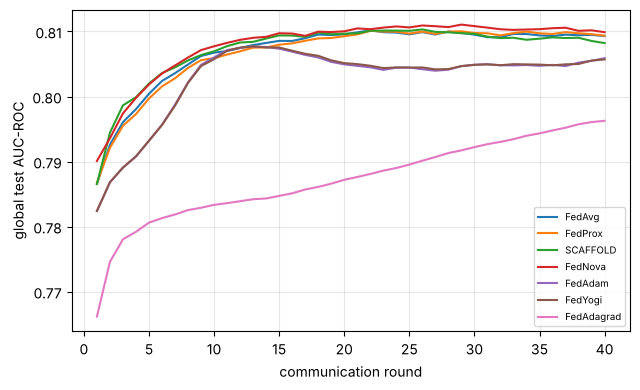

Significance vs FedAvg (F1, Holm-corrected):


,method,mean_diff,p_wilcoxon,p_ttest,p_holm,significant@0.05
0,FedNova,0.004158,0.359375,0.276392,1.0,False
1,FedAdagrad,0.006339,0.375000,0.461511,1.0,False
2,SCAFFOLD,-0.004178,0.431641,0.467709,1.0,False
3,FedYogi,-0.002475,0.431641,0.353177,1.0,False
4,FedAdam,-0.002110,0.492188,0.457684,1.0,False
5,FedProx,0.000308,0.812500,0.852033,1.0,False


done in 11s


In [18]:
if "algorithms" in RUN:
    t0 = time.perf_counter()
    df1, h1 = exp_algorithms(raw, SEED_LIST, ROUNDS)
    save_result("exp1_algorithms", df1, h1, list(df1.name.unique()))
    print("Significance vs FedAvg (F1, Holm-corrected):")
    display(significance(df1, "FedAvg"))
    print(f"done in {time.perf_counter() - t0:.0f}s")

### Experiment 2 — privacy-preserving techniques (RQ1, RQ6)

--- exp2_privacy ---


,accuracy,precision,recall,f1,auc,conv_rounds,comm_kb,time_s,epsilon
name,,,,,,,,,
FedProx (no privacy),0.7371 ± 0.0218,0.7436 ± 0.0278,0.7931 ± 0.0192,0.7674 ± 0.021,0.81 ± 0.019,9.0 ± 3.2998,35.9375 ± 0.0,0.0708 ± 0.0052,NaN
DP-SGD eps=1,0.6384 ± 0.0405,0.6474 ± 0.0333,0.7557 ± 0.0992,0.6936 ± 0.044,0.6923 ± 0.0596,41.0 ± 0.0,35.9375 ± 0.0,0.2339 ± 0.0184,1.0 ± 0.0
DP-SGD eps=5,0.7211 ± 0.0214,0.7125 ± 0.0227,0.8249 ± 0.0415,0.7638 ± 0.0185,0.7964 ± 0.021,35.3 ± 10.6254,35.9375 ± 0.0,0.2402 ± 0.0257,5.0 ± 0.0
DP-SGD eps=10,0.7289 ± 0.0155,0.7205 ± 0.0212,0.8264 ± 0.0329,0.7692 ± 0.0132,0.8024 ± 0.0197,31.3 ± 13.8728,35.9375 ± 0.0,0.2393 ± 0.0327,10.0 ± 0.0
Local DP eps=5,0.5836 ± 0.062,0.6226 ± 0.0811,0.6242 ± 0.1493,0.6138 ± 0.0898,0.6114 ± 0.0781,41.0 ± 0.0,35.9375 ± 0.0,0.0718 ± 0.0053,5.0 ± 0.0
Local DP eps=10,0.606 ± 0.0595,0.6334 ± 0.0703,0.6705 ± 0.1213,0.6462 ± 0.0778,0.6496 ± 0.0693,41.0 ± 0.0,35.9375 ± 0.0,0.0728 ± 0.0076,10.0 ± 0.0
Secure aggregation,0.7371 ± 0.0218,0.7436 ± 0.0278,0.7931 ± 0.0192,0.7674 ± 0.021,0.81 ± 0.019,9.0 ± 3.2998,60.9375 ± 0.0,0.0995 ± 0.0128,NaN
DP-SGD eps=5 + SecAgg,0.7211 ± 0.0214,0.7125 ± 0.0227,0.8249 ± 0.0415,0.7638 ± 0.0185,0.7964 ± 0.021,35.3 ± 10.6254,60.9375 ± 0.0,0.2645 ± 0.0173,5.0 ± 0.0
Homomorphic enc. (Paillier),0.7323 ± 0.0178,0.7276 ± 0.0285,0.8182 ± 0.0251,0.7697 ± 0.0169,0.8045 ± 0.0193,8.4 ± 2.2211,291.9922 ± 0.0,16.2389 ± 0.4071,NaN


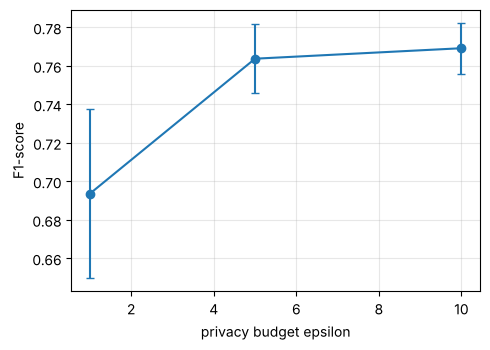

done in 357s


In [19]:
if "privacy" in RUN:
    t0 = time.perf_counter()
    use_he = (not SKIP_HE) and HAVE_PHE
    if not use_he:
        print("Homomorphic-encryption run skipped (SKIP_HE or python-paillier missing).")
    df2, h2 = exp_privacy(raw, SEED_LIST, ROUNDS, with_he=use_he)
    save_result("exp2_privacy", df2)
    plot_privacy_utility(df2, f"{OUT_DIR}/exp2_privacy_utility.png")
    print(f"done in {time.perf_counter() - t0:.0f}s")

### Experiment 3 — security: robust aggregation and adversarial training (RQ7)
12 clients (each hospital cut into 3 shards), 3 of them malicious.

In [20]:
if "security" in RUN:
    t0 = time.perf_counter()
    df3, h3 = exp_security(raw, SEED_LIST, ROUNDS)
    df3.to_csv(f"{OUT_DIR}/exp3_security.csv", index=False)
    print("--- exp3_security (mean F1; rows = aggregation rule, columns = attack) ---")
    display(df3.pivot_table(index="aggregator", columns="attack", values="f1").round(3))
    print("--- accuracy on FGSM-perturbed test records (no attacker) ---")
    display(df3[df3.attack == "none"].groupby("aggregator")["adv_accuracy"].mean().round(3).to_frame())
    print(f"done in {time.perf_counter() - t0:.0f}s")

--- exp3_security (mean F1; rows = aggregation rule, columns = attack) ---


attack,gaussian,label_flip,none,sign_flip
aggregator,,,,
krum,0.699,0.643,0.735,0.695
mean,0.754,0.636,0.774,0.000
mean + AT,0.705,0.124,0.739,0.000
median,0.712,0.635,0.760,0.631
multikrum,0.732,0.646,0.778,0.737
trimmed,0.731,0.631,0.765,0.603


--- accuracy on FGSM-perturbed test records (no attacker) ---


,adv_accuracy
aggregator,
krum,0.212
mean,0.195
mean + AT,0.454
median,0.197
multikrum,0.229
trimmed,0.209


done in 35s


### Experiment 4 — communication-efficient techniques (RQ7)

--- exp4_communication ---


,accuracy,precision,recall,f1,auc,conv_rounds,comm_kb,time_s,epsilon
name,,,,,,,,,
FedAvg (float32),0.7457 ± 0.0194,0.7443 ± 0.0285,0.8161 ± 0.0154,0.7783 ± 0.0183,0.8093 ± 0.0186,16.5 ± 6.1869,35.9375 ± 0.0,0.04 ± 0.0053,NaN
"FedPAQ (E=4, 8-bit, 50% clients)",0.725 ± 0.03,0.7254 ± 0.0436,0.8137 ± 0.1004,0.7618 ± 0.0415,0.8077 ± 0.0218,5.7 ± 2.3118,2.4023 ± 0.0,0.0142 ± 0.0017,NaN
Quantised 8-bit,0.7457 ± 0.0194,0.7443 ± 0.0285,0.8161 ± 0.0154,0.7783 ± 0.0183,0.8094 ± 0.0186,16.5 ± 6.1869,24.0234 ± 0.0,0.0474 ± 0.0077,NaN
Quantised 4-bit,0.7448 ± 0.0195,0.7436 ± 0.029,0.8152 ± 0.0139,0.7775 ± 0.0184,0.8094 ± 0.0185,16.3 ± 6.1292,21.875 ± 0.0,0.0443 ± 0.0071,NaN
Quantised 2-bit,0.7422 ± 0.0177,0.7389 ± 0.0249,0.8183 ± 0.0126,0.7764 ± 0.0168,0.8094 ± 0.0184,17.0 ± 6.1101,20.7031 ± 0.0,0.0427 ± 0.0032,NaN
Top-k 30% + error feedback,0.7422 ± 0.0206,0.7429 ± 0.0283,0.8098 ± 0.0154,0.7746 ± 0.0182,0.8095 ± 0.0178,16.4 ± 5.6999,28.9062 ± 0.0,0.0437 ± 0.0071,NaN
Top-k 10% + error feedback,0.7405 ± 0.0169,0.7441 ± 0.0253,0.8028 ± 0.0146,0.772 ± 0.0135,0.8082 ± 0.0204,16.3 ± 4.7854,21.0938 ± 0.0,0.0446 ± 0.0093,NaN


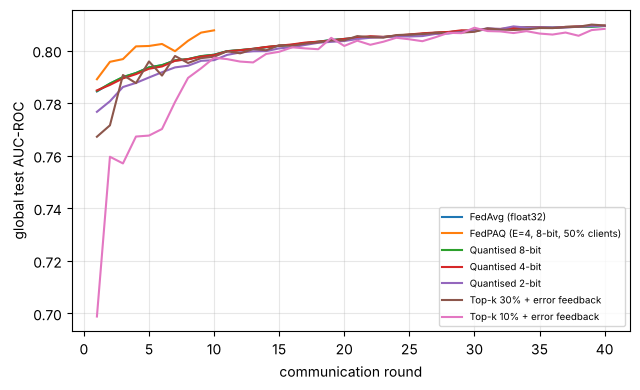

done in 3s


In [21]:
if "communication" in RUN:
    t0 = time.perf_counter()
    df4, h4 = exp_communication(raw, SEED_LIST, ROUNDS)
    save_result("exp4_communication", df4, h4, list(df4.name.unique()))
    print(f"done in {time.perf_counter() - t0:.0f}s")

### Experiment 5 — the recommended 8-configuration framework (Table 7)

--- exp5_framework ---


,accuracy,precision,recall,f1,auc,conv_rounds,comm_kb,time_s,epsilon
name,,,,,,,,,
FedAvg,0.7349 ± 0.0226,0.7419 ± 0.0282,0.7907 ± 0.0213,0.7653 ± 0.0222,0.8099 ± 0.0193,8.4 ± 3.3731,35.9375 ± 0.0,0.0618 ± 0.003,NaN
FedProx,0.7371 ± 0.0218,0.7436 ± 0.0278,0.7931 ± 0.0192,0.7674 ± 0.021,0.81 ± 0.019,9.0 ± 3.2998,35.9375 ± 0.0,0.0685 ± 0.0032,NaN
SCAFFOLD,0.7332 ± 0.0215,0.7597 ± 0.0242,0.75 ± 0.0234,0.7546 ± 0.0198,0.8093 ± 0.0198,8.2 ± 2.7809,71.875 ± 0.0,0.0699 ± 0.0076,NaN
FedAdam,0.7302 ± 0.0232,0.7389 ± 0.0263,0.7835 ± 0.0263,0.7604 ± 0.0234,0.8075 ± 0.0191,6.7 ± 1.8288,35.9375 ± 0.0,0.0634 ± 0.0052,NaN
FedAvg + DP,0.722 ± 0.0207,0.7134 ± 0.0233,0.8249 ± 0.0415,0.7643 ± 0.0187,0.7966 ± 0.0214,35.3 ± 10.6254,35.9375 ± 0.0,0.2248 ± 0.0101,5.0 ± 0.0
FedProx + DP,0.7211 ± 0.0214,0.7125 ± 0.0227,0.8249 ± 0.0415,0.7638 ± 0.0185,0.7964 ± 0.021,35.3 ± 10.6254,35.9375 ± 0.0,0.2319 ± 0.0274,5.0 ± 0.0
FedProx + SecAgg,0.7371 ± 0.0218,0.7436 ± 0.0278,0.7931 ± 0.0192,0.7674 ± 0.021,0.81 ± 0.019,9.0 ± 3.2998,60.9375 ± 0.0,0.101 ± 0.0135,NaN
FedProx + DP + SecAgg,0.7211 ± 0.0214,0.7125 ± 0.0227,0.8249 ± 0.0415,0.7638 ± 0.0185,0.7964 ± 0.021,35.3 ± 10.6254,60.9375 ± 0.0,0.2696 ± 0.0274,5.0 ± 0.0


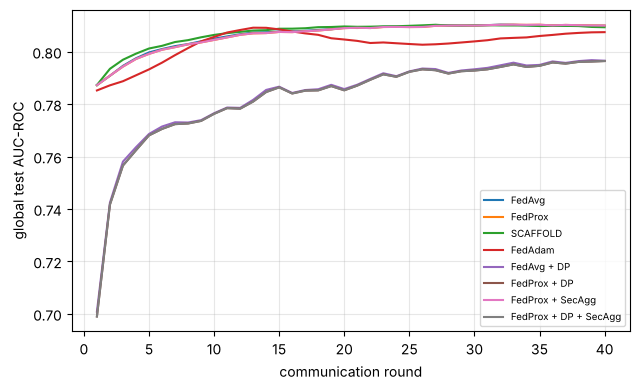

Mean over seeds:


,accuracy,precision,recall,f1,auc,conv_rounds,comm_kb,time_s,epsilon,utility_loss_%,poison_retention_%
name,,,,,,,,,,,
FedAvg,0.735,0.742,0.791,0.765,0.810,8.4,35.938,0.062,NaN,0.000,85.147
FedProx,0.737,0.744,0.793,0.767,0.810,9.0,35.938,0.069,NaN,0.000,84.998
SCAFFOLD,0.733,0.760,0.750,0.755,0.809,8.2,71.875,0.070,NaN,0.000,90.208
FedAdam,0.730,0.739,0.784,0.760,0.807,6.7,35.938,0.063,NaN,0.000,84.753
FedAvg + DP,0.722,0.713,0.825,0.764,0.797,35.3,35.938,0.225,5.0,0.105,79.315
FedProx + DP,0.721,0.712,0.825,0.764,0.796,35.3,35.938,0.232,5.0,0.438,79.056
FedProx + SecAgg,0.737,0.744,0.793,0.767,0.810,9.0,60.938,0.101,NaN,0.000,84.998
FedProx + DP + SecAgg,0.721,0.712,0.825,0.764,0.796,35.3,60.938,0.270,5.0,0.438,79.056


Significance vs FedAvg (F1):


,method,mean_diff,p_wilcoxon,p_ttest,p_holm,significant@0.05
0,SCAFFOLD,-0.010738,0.064453,0.045225,0.451172,False
1,FedProx,0.002027,0.218750,0.107666,1.000000,False
2,FedProx + SecAgg,0.002027,0.218750,0.107666,1.000000,False
3,FedAdam,-0.004954,0.232422,0.193327,1.000000,False
4,FedProx + DP + SecAgg,-0.001585,0.845703,0.783541,1.000000,False
5,FedProx + DP,-0.001585,0.845703,0.783541,1.000000,False
6,FedAvg + DP,-0.001072,1.000000,0.847356,1.000000,False


Significance vs FedProx (AUC):


,method,mean_diff,p_wilcoxon,p_ttest,p_holm,significant@0.05
0,FedAvg + DP,-0.013382,0.001953,0.004436,0.013672,True
1,FedProx + DP,-0.013514,0.003906,0.003540,0.023438,True
2,FedProx + DP + SecAgg,-0.013506,0.003906,0.003564,0.023438,True
3,FedAdam,-0.002494,0.083984,0.103843,0.335938,False
4,SCAFFOLD,-0.000617,0.695312,0.667959,1.000000,False
5,FedAvg,-0.000018,0.921875,0.896098,1.000000,False
6,FedProx + SecAgg,0.000000,1.000000,1.000000,1.000000,False


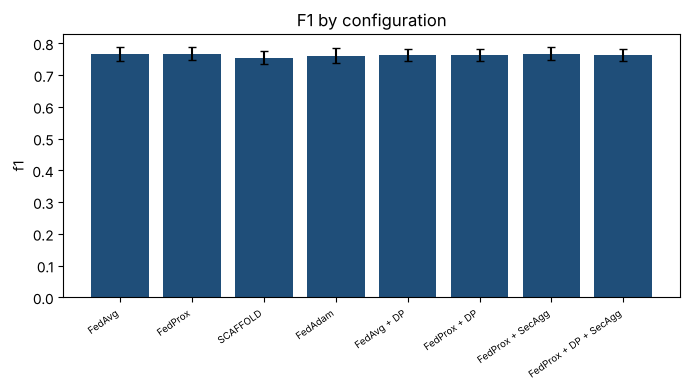

done in 291s


In [22]:
if "framework" in RUN:
    t0 = time.perf_counter()
    df5, h5 = exp_framework(raw, SEED_LIST, ROUNDS)
    cols = METRICS + ["conv_rounds", "comm_kb", "time_s", "epsilon", "utility_loss_%", "poison_retention_%"]
    save_result("exp5_framework", df5, h5, list(df5.name.unique()))
    print("Mean over seeds:")
    display(df5.groupby("name", sort=False)[cols].mean().round(3))
    print("Significance vs FedAvg (F1):")
    display(significance(df5, "FedAvg", "f1"))
    print("Significance vs FedProx (AUC):")
    display(significance(df5, "FedProx", "auc"))
    plot_bars(df5, "f1", f"{OUT_DIR}/exp5_f1.png", "F1 by configuration")
    print(f"done in {time.perf_counter() - t0:.0f}s")

## 7. Output files

In [23]:
for f in sorted(os.listdir(OUT_DIR)):
    print(f"{OUT_DIR}/{f}")

results/exp1_algorithms.csv
results/exp1_algorithms_auc.png
results/exp2_privacy.csv
results/exp2_privacy_utility.png
results/exp3_security.csv
results/exp4_communication.csv
results/exp4_communication_auc.png
results/exp5_f1.png
results/exp5_framework.csv
results/exp5_framework_auc.png


---
**Reading the results.** The shared test set is the pooled 20 % hold-out of every hospital. A configuration only beats another in a statistically meaningful way if its Holm-corrected p-value is below 0.05 (`significant@0.05` column). Differences of a point or two of F1 between algorithms usually are *not* significant on four small hospitals, which is a finding in its own right.
Two limitations from the report still apply: secure aggregation is simulated (masking is real, key agreement and dropout recovery are not), and the ε values are accountant estimates rather than audited guarantees.